In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

REQUISIÇÃO DOS DADOS PARA FORMATO CSV

In [ ]:
url = "https://apidadosabertos.saude.gov.br/vacinacao/doses-aplicadas-pni-2025?"

params = {
    "limit": 1000,
    "offset" : 0
}

headers = {
    "accept" : "text/csv"
}

response = requests.get(url, params=params, headers=headers, timeout=30)

TRANSFORMANDO EM UM DATA FRAME

In [ ]:
dados = StringIO(response.text)

if response.status_code == 200:
    df_2025 = pd.read_csv(dados, sep=';')

DETALHES DA BASE DE DADOS

In [ ]:
print(df_2025.head())

  descricao_natureza_estabelecimento  codigo_via_administracao  \
0              ADMINISTRACAO PUBLICA                         0   
1              ADMINISTRACAO PUBLICA                         0   
2              ADMINISTRACAO PUBLICA                     10916   
3              ADMINISTRACAO PUBLICA                     10916   
4             ENTIDADES EMPRESARIAIS                     10916   

  nome_pais_paciente  codigo_origem_registro  codigo_pais_paciente  \
0             BRASIL                     NaN                  10.0   
1             BRASIL                     NaN                  10.0   
2             BRASIL                     NaN                  10.0   
3             BRASIL                     NaN                  10.0   
4             BRASIL                     NaN                  10.0   

  nome_raca_cor_paciente sigla_vacina  codigo_vacina_fabricante  \
0                  PARDA          DNG                       NaN   
1                  PARDA          DNG           

In [ ]:
df_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 56 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   descricao_natureza_estabelecimento      1000 non-null   object 
 1   codigo_via_administracao                1000 non-null   int64  
 2   nome_pais_paciente                      989 non-null    object 
 3   codigo_origem_registro                  36 non-null     float64
 4   codigo_pais_paciente                    989 non-null    float64
 5   nome_raca_cor_paciente                  1000 non-null   object 
 6   sigla_vacina                            1000 non-null   object 
 7   codigo_vacina_fabricante                548 non-null    float64
 8   data_vacina                             1000 non-null   object 
 9   codigo_condicao_maternal                61 non-null     float64
 10  nome_razao_social_estabelecimento       1000 non-null   objec

In [ ]:
df_2025.describe()

,codigo_via_administracao,codigo_origem_registro,codigo_pais_paciente,codigo_vacina_fabricante,codigo_condicao_maternal,codigo_sistema_origem,codigo_municipio_estabelecimento,data_deletado_rnds,numero_cep_paciente,codigo_etnia_indigena_paciente,...,codigo_tipo_estabelecimento,codigo_natureza_estabelecimento,codigo_raca_cor_paciente,codigo_vacina_grupo_atendimento,codigo_municipio_paciente,codigo_local_aplicacao,codigo_vacina,codigo_estrategia_vacinacao,codigo_troca_documento,codigo_dose_vacina
count,1000.000000,36.000000,989.0,548.000000,61.0,1000.000000,1000.000000,0.0,917.000000,2.000000,...,1000.000000,1000.00000,1000.000000,175.000000,989.000000,1000.000000,1000.000000,995.000000,0.0,1000.000000
mean,2433.743000,79.944444,10.0,21305.855839,1.0,21521.660000,340578.818000,NaN,45104.856052,107.500000,...,4.892000,1.02900,22.292000,218.491429,338305.294237,2.293000,80.600000,1.170854,NaN,5.604000
std,4545.170522,39.335876,0.0,19448.775715,0.0,6460.521358,102337.362241,NaN,29075.894926,70.003571,...,13.149877,0.17375,39.222432,98.414843,102533.015214,7.014582,39.496835,1.076059,NaN,10.159843
min,0.000000,1.000000,10.0,149.000000,1.0,16341.000000,110002.000000,NaN,1257.000000,58.000000,...,1.000000,1.00000,1.000000,0.000000,110002.000000,0.000000,14.000000,1.000000,NaN,1.000000
25%,0.000000,99.000000,10.0,149.000000,1.0,18602.000000,292740.000000,NaN,15700.000000,82.750000,...,2.000000,1.00000,1.000000,210.000000,291800.000000,0.000000,14.000000,1.000000,NaN,1.000000
50%,0.000000,99.000000,10.0,39262.000000,1.0,18602.000000,350945.000000,NaN,41760.000000,107.500000,...,2.000000,1.00000,3.000000,210.000000,350760.000000,0.000000,104.000000,1.000000,NaN,2.000000
75%,0.000000,99.000000,10.0,39262.000000,1.0,19788.000000,355170.000000,NaN,71660.000000,132.250000,...,2.000000,1.00000,4.000000,210.000000,355030.000000,0.000000,104.000000,1.000000,NaN,2.000000
max,10916.000000,99.000000,10.0,39263.000000,1.0,44375.000000,530010.000000,NaN,99999.000000,157.000000,...,85.000000,3.00000,99.000000,927.000000,530010.000000,99.000000,104.000000,8.000000,NaN,38.000000


## Realizando a limpeza

Retirando linhas e colunas com valores nulos

In [ ]:
df_2025 = df_2025.dropna(how='all')
df_2025 = df_2025.dropna(axis=1, thresh=len(df_2025) * 0.6)


Retirando colunas que não serão utilizadas e dando um index ao dataframe

In [ ]:
print("INFO")
print(df_2025.info())

print("CÓDIGO DO DOCUMENTO")
print(df_2025['codigo_documento'])

print("DATAFRAME")
print(df_2025)

print("LISTA DE COLUNAS")
print(df_2025.columns)

INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 43 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   descricao_natureza_estabelecimento  1000 non-null   object 
 1   codigo_via_administracao            1000 non-null   int64  
 2   nome_pais_paciente                  989 non-null    object 
 3   codigo_pais_paciente                989 non-null    float64
 4   nome_raca_cor_paciente              1000 non-null   object 
 5   sigla_vacina                        1000 non-null   object 
 6   data_vacina                         1000 non-null   object 
 7   nome_razao_social_estabelecimento   1000 non-null   object 
 8   sigla_uf_estabelecimento            1000 non-null   object 
 9   nome_municipio_estabelecimento      1000 non-null   object 
 10  codigo_sistema_origem               1000 non-null   int64  
 11  status_documento                    100

In [ ]:
if df_2025['codigo_documento'].is_unique: df_2025.set_index('codigo_documento', inplace=True)
df_2025.index.name

'codigo_documento'

Pegando apenas as colunas que desejo para fazer diferentes análises

In [ ]:
new_columns = ['descricao_natureza_estabelecimento','nome_raca_cor_paciente', 'sigla_vacina', 'data_vacina',
       'nome_razao_social_estabelecimento', 'sigla_uf_estabelecimento','nome_municipio_estabelecimento','status_documento', 'descricao_tipo_estabelecimento',
       'descricao_estrategia_vacinacao', 'nome_uf_paciente','descricao_local_aplicacao','numero_idade_paciente','descricao_vacina_fabricante','codigo_paciente',
       'descricao_sistema_origem','nome_municipio_paciente', 'nome_fantasia_estalecimento', 'sigla_uf_paciente','codigo_vacina',
       'descricao_via_administracao','descricao_vacina', 'data_entrada_rnds', 'tipo_sexo_paciente','descricao_nacionalidade_paciente','descricao_dose_vacina']

df_2025 = df_2025[new_columns]

df_2025.iloc[:5, 10:20]

,nome_uf_paciente,descricao_local_aplicacao,numero_idade_paciente,descricao_vacina_fabricante,codigo_paciente,descricao_sistema_origem,nome_municipio_paciente,nome_fantasia_estalecimento,sigla_uf_paciente,codigo_vacina
codigo_documento,,,,,,,,,,
109e0783-8547-437f-b759-8d01b6696859-i0b0,SAO PAULO,Sem registro no sistema de informaÃ§Ã£o de origem,10,IDT BIOLOGIKA GMBH,26459eaaa37d30871a151d659374fc4ab2558954198b65...,ESUS APS - NACIONAL (OFFLINE),ITAQUAQUECETUBA,UBS JARDIM DO CARMO,SP,104
18cd54f9-f6c7-4d9b-b908-0f7cab5f8634-i0b0,GOIAS,Sem registro no sistema de informaÃ§Ã£o de origem,33,IDT BIOLOGIKA GMBH,2872a3a07f2f1cf0727f57244bff260912b8ca152ff3e9...,ESUS APS - NACIONAL (OFFLINE),POSSE,POSTO DE SAUDE MAE BELA POSSE,GO,104
169c5499-8f5e-4f4c-bc22-9022da12249e-i0b0,MINAS GERAIS,DeltÃ³ide Direito,12,IDT BIOLOGIKA GMBH,9f0d779c0590e2eefb38b742be0a8de475660def32c047...,SIGRAH,BELO HORIZONTE,CENTRO DE SAUDE SAO MIGUEL ARCANJO,MG,104
41d6892c-fe6d-4d58-834c-6c9fdd0e10d7-i0b0,MINAS GERAIS,DeltÃ³ide Esquerdo,12,IDT BIOLOGIKA GMBH,7aa13a4540d92d4943beed641d95d12b431d29689e4b1a...,FAST MEDIC - FAST SAUDE,UBERLANDIA,UBSF SAO JOSE,MG,104
41db9ef9-c8c3-4afc-a322-6c78789d0417-i0b0,SAO PAULO,Face Anterolateral Externa do BraÃ§o Esquerdo,68,IDT BIOLOGIKA GMBH,3051594d0b98bf75149e77ac91c11b0bbf070895245471...,Novo PNI,MAIRIPORA,HOSPITAL NOVO ATIBAIA,SP,104


VERIFICANDO:

 * Tipo das colunas
 * Nomes das Colunas
 * Padronização de Strings
 * Duplicatas
 * Outliers
 * Valores Nulos

In [ ]:
df_2025.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 109e0783-8547-437f-b759-8d01b6696859-i0b0 to ec6df514-e2ec-4f94-8cce-7d9ec415b802-i0b0
Data columns (total 26 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   descricao_natureza_estabelecimento  1000 non-null   object
 1   nome_raca_cor_paciente              1000 non-null   object
 2   sigla_vacina                        1000 non-null   object
 3   data_vacina                         1000 non-null   object
 4   nome_razao_social_estabelecimento   1000 non-null   object
 5   sigla_uf_estabelecimento            1000 non-null   object
 6   nome_municipio_estabelecimento      1000 non-null   object
 7   status_documento                    1000 non-null   object
 8   descricao_tipo_estabelecimento      1000 non-null   object
 9   descricao_estrategia_vacinacao      995 non-null    object
 10  nome_uf_paciente                    989 non-null

In [ ]:
columns_date = ['data_vacina', 'data_entrada_rnds']

for column in columns_date:
    df_2025[column] = pd.to_datetime(df_2025[column], errors='coerce')

columns_string = [
    column for column in df_2025.columns
    if df_2025[column].dtype == 'object'
]

print(columns_string)

for column in columns_string:
    df_2025[column] = df_2025[column].astype("string").str.capitalize()

df_2025.info()

['descricao_natureza_estabelecimento', 'nome_raca_cor_paciente', 'sigla_vacina', 'nome_razao_social_estabelecimento', 'sigla_uf_estabelecimento', 'nome_municipio_estabelecimento', 'status_documento', 'descricao_tipo_estabelecimento', 'descricao_estrategia_vacinacao', 'nome_uf_paciente', 'descricao_local_aplicacao', 'descricao_vacina_fabricante', 'codigo_paciente', 'descricao_sistema_origem', 'nome_municipio_paciente', 'nome_fantasia_estalecimento', 'sigla_uf_paciente', 'descricao_via_administracao', 'descricao_vacina', 'tipo_sexo_paciente', 'descricao_nacionalidade_paciente', 'descricao_dose_vacina']
<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 109e0783-8547-437f-b759-8d01b6696859-i0b0 to ec6df514-e2ec-4f94-8cce-7d9ec415b802-i0b0
Data columns (total 26 columns):
 #   Column                              Non-Null Count  Dtype                    
---  ------                              --------------  -----                    
 0   descricao_natureza_estabelecimento  1000 n

Duplicatas: não há

In [ ]:
print(df_2025.duplicated().sum())

0


Outliers

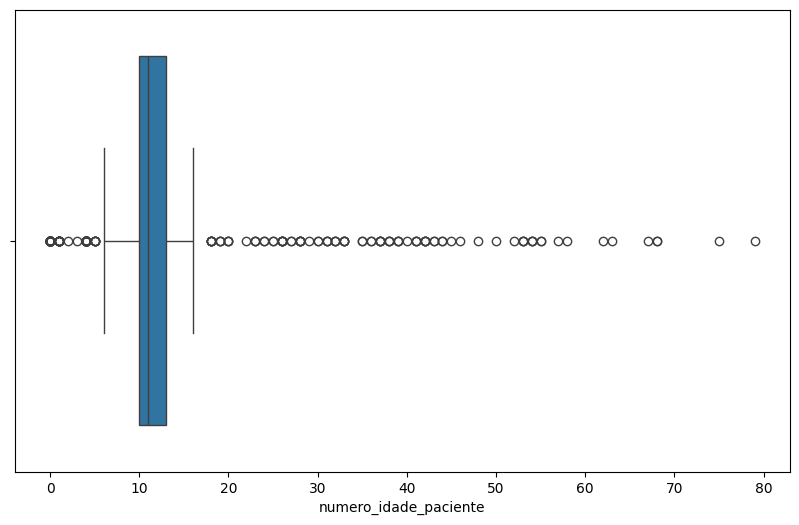

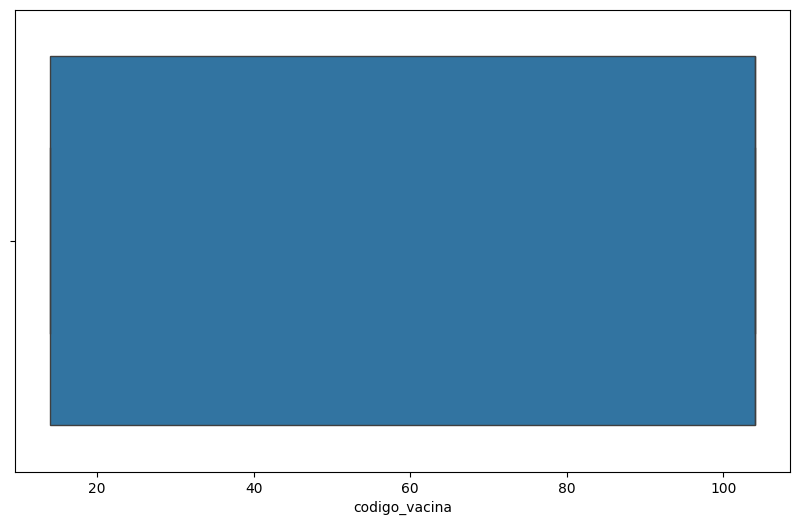

Idade Menor:  0
Idade Maior:  79


In [ ]:
columns_int = [
    column for column in df_2025.columns
    if df_2025[column].dtype == 'int64'
]

for column in columns_int:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df_2025, x=column)
    plt.show()

print("Idade Menor: ", df_2025['numero_idade_paciente'].min())
print("Idade Maior: ", df_2025['numero_idade_paciente'].max())

Valores Nulos: os valores inteiros que existem são a idade e o código da vacina, o que não o torna necessário modificar

### Gráficos

O gráfico abaixo mostra a quantidade de vacinas realizadas em pessoas de cada sexo, e dentro do que foi mostrado não uma diferença muito significativa

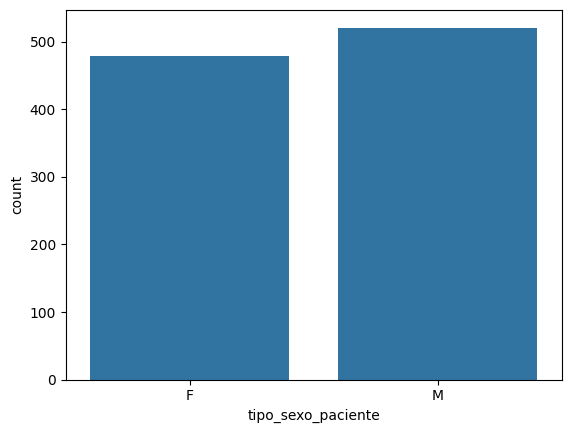

In [ ]:
sns.countplot(data=df_2025, x='tipo_sexo_paciente') #um tipo de gráfico que já conta o número de ocorrências implicitamente
plt.ylabel("Quantidade")
plt.show()

In [ ]:
print("IDADE")
print("MODA: ", df_2025['numero_idade_paciente'].mode()[0])
print("MÉDIA: ", round(df_2025['numero_idade_paciente'].mean()))
print("MEDIANA: ", round(df_2025['numero_idade_paciente'].median()))
print("DESVIO PADRÃO: ", round(df_2025['numero_idade_paciente'].std()))

IDADE
MODA:  10
MÉDIA:  12
MEDIANA:  11
DESVIO PADRÃO:  10


Relação entre a idade e quantidade de vacinas

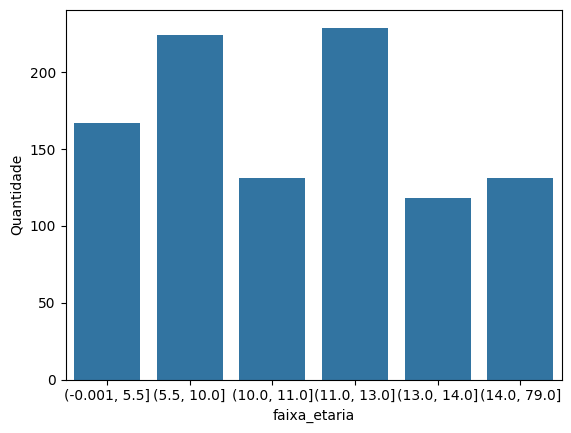

In [ ]:
df_2025['faixa_etaria'] = pd.qcut(df_2025['numero_idade_paciente'], q=6, duplicates= 'drop')

sns.countplot(data=df_2025, x='faixa_etaria')
plt.ylabel("Quantidade")
plt.show()

Verifica-se que crianças pequenas tomam mais vacinas que outras, assim como tomam mais vacinas antes de virarem adultos